In [201]:
import pandas as pd
import numpy as np
import pickle
from rdkit import Chem
from rdkit.Chem import AllChem
from rdkit.Chem import Descriptors
from rdkit.Chem import rdMolDescriptors
from scipy import stats

In [218]:
def load_pickle(fname):
    with open(f"results/{fname}.pkl", "rb") as f:
        cpnd_list = pickle.load(f)
    return cpnd_list

In [72]:
def unique_and_overlapping(all_feat_smiles, cc_feat_smiles):
    # Compounds unique to all feature model:
    all_feat_uniq = list(set(all_feat_smiles) - set(cc_feat_smiles))
    print(f"Unique compounds - All Feature Model: {len(all_feat_uniq)}")

    # Compounds unique to cell count feature model:
    cc_feat_uniq = list(set(cc_feat_smiles) - set(all_feat_smiles))
    print(f"Unique compounds - Cell Count Model: {len(cc_feat_uniq)}")

    # Create a combined dataframe of uniquely predicted compounds for easier processing and comparison later:
    all_uniq_smiles = all_feat_uniq + cc_feat_uniq
    model_source = ['all_feat'] * len(all_feat_uniq) + ['cc_feat'] * len(cc_feat_uniq)

    df = pd.DataFrame({
            'smiles': all_uniq_smiles,
            'model_source': model_source
        })

    # Calculate the shared compounds between the models:
    shared = list(set(all_feat_smiles) & set(cc_feat_smiles))
    all_smiles = list(set(all_feat_smiles + cc_feat_smiles))
    print(f"Overlap between models: {100* len(shared) / len(all_smiles):.2f}% ({len(shared)}/{len(all_smiles)})")

    return df

In [64]:
def get_physicochemical_descriptors(smiles): 
    mol = Chem.MolFromSmiles(smiles) 
    if mol is None: 
        # Handle invalid SMILES 
        print(f"Warning: Could not process SMILES: {smiles}") 
        # Return None for each descriptor if conversion fails 
        return None, None, None, None, None, None, None, None 
    # Calculate desired descriptors 
    mw = Descriptors.MolWt(mol) 
    logp = Descriptors.MolLogP(mol) 
    tpsa = Descriptors.TPSA(mol) # Topological Polar Surface Area 
    hbd = Descriptors.NumHDonors(mol) # Number of Hydrogen Bond Donors 
    hba = Descriptors.NumHAcceptors(mol) # Number of Hydrogen Bond Acceptors 
    rotatable_bonds = Descriptors.NumRotatableBonds(mol) # Number of Rotatable Bonds 
    formal_charge = Chem.GetFormalCharge(mol) # Total Formal Charge 

    return mol, mw, logp, tpsa, hbd, hba, rotatable_bonds, formal_charge 

In [206]:
def visualize_descriptors(df, properties):
    fig, axes = plt.subplots(2, 3, figsize=(18, 10))
    axes = axes.flatten()
    
    for i, prop in enumerate(properties):
        sns.histplot(data=df,
                     x=prop,
                     hue='model_source',
                     kde=True,
                     palette='Set2',
                     multiple='layer',
                     ax=axes[i])
        axes[i].set_title(f'Distribution of {prop}')
        axes[i].set_xlabel(prop)
        axes[i].set_ylabel('Number of Compounds')
        axes[i].grid(axis='y', alpha=0.75)
    
    plt.tight_layout()
    plt.show()

In [207]:
def stat_tests(df, properties):
    for prop in properties: 
        if prop not in ['FormalCharge', 'NumRings', 'HBD', 'HBA']: # For these, consider non-parametric or chi-square 
            data_A = df[df['model_source'] == 'all_feat'][prop] 
            data_B = df[df['model_source'] == 'cc_feat'][prop] 
            if not data_A.empty and not data_B.empty: 
                t_stat, p_value = stats.ttest_ind(data_A, data_B, equal_var=False) # Welch's t-test 
                print(f"\n--- Statistical Test ({prop}) ---") 
                print(f"Mean {prop} (All Feat.): {data_A.mean():.2f}") 
                print(f"Mean {prop} (Cell Feat.): {data_B.mean():.2f}") 
                print(f"T-statistic: {t_stat:.2f}") 
                print(f"P-value: {p_value:.3f}") 
                if p_value < 0.05: 
                    print(f"There is a statistically significant difference in {prop} between the two models' predictions.") 
                else: 
                    print(f"No statistically significant difference in {prop} between the two models' predictions.") 
                
        else: 
            print(f"\nNot enough data to perform statistical test for {prop}.")

In [82]:
def get_descriptors(df):
    # Return the physicochemical descriptors for each compound smiles:
    df[['Molecule_Object', 'MW', 'MolLogP', 'TPSA', 'HBD', 'HBA', 'RotatableBonds', 'FormalCharge']] = df['smiles'].apply( 
        lambda s: pd.Series(get_physicochemical_descriptors(s)) ) 
    
    # Filter out any rows where molecule conversion failed 
    df = df.dropna(subset=['Molecule_Object']).copy() 

    # Plot distribution plots:
    properties_to_plot = ['MW', 'MolLogP', 'TPSA', 'HBD', 'HBA', 'RotatableBonds']
    visualize_descriptors(df, properties_to_plot)

    # Perform significance testing:
    stat_tests(df, properties_to_plot)

# Load Data:

## All Feature Model:

- Note: Many compounds are tested across multiple assays, therefore any duplicates in the below lists are removed when loading.

In [219]:
all_tp = list(set(load_pickle("tp_all_feat")))
all_fp = list(set(load_pickle("fp_all_feat")))
all_tn = list(set(load_pickle("tn_all_feat")))
all_fn = list(set(load_pickle("fn_all_feat")))

## Cell Count Feature Model:

In [8]:
cc_tp = list(set(load_pickle("tp_cc_feat")))
cc_fp = list(set(load_pickle("fp_cc_feat")))
cc_tn = list(set(load_pickle("tn_cc_feat")))
cc_fn = list(set(load_pickle("fn_cc_feat")))

# Physicochemical Comparison Analysis:

### !! NOTE:

The number of true positives, false positives, true negatives and false negatives below will not sum perfectly. To illustrate this here's an example:

Imagine Compound A is tested for bioactivity in 5 of the assays (see Cell Count Baseline - Logistic Regression (Moshkov Dataset). Each model is trained separately for each assay, and the compound's activity is not necessarilly the same across assays.

Model X:

Assay 1: Cpnd A is active, and predicted as active. True positive.

Assay 2: Cpnd A is active, and predicted as active. True positive.

Assay 3: Cpnd A is inactive, and predicted as inactive. True negative.

Assay 4: Cpnd A is inactive, and predicted as active. False positive.

Assay 5: Cpnd A is active, and predicted as inactive. False negative.

Below we are analysing how many *unique* compounds are within each predictive category for each model. So in this example Compound A would be represented once in each category (as it's included twice as a true positive and then amalgamated). 


## True Positives:

In [75]:
tp_df = unique_and_overlapping(all_tp, cc_tp)
tp_df.head(3)

Unique compounds - All Feature Model: 1999
Unique compounds - Cell Count Model: 1065
Overlap between models: 49.54% (3008/6072)


,smiles,model_source
0,C\C=C\Cn1c(SCc2ccccc2)nc2n(C)c(=O)[nH]c(=O)c12,all_feat
1,C[C@H](CO)N1C[C@@H](C)[C@@H](CN(C)Cc2ccc3OCCOc...,all_feat
2,Cn1c(Cc2ccccc2)nc2n(C)c(=O)n(C)c(=O)c12,all_feat


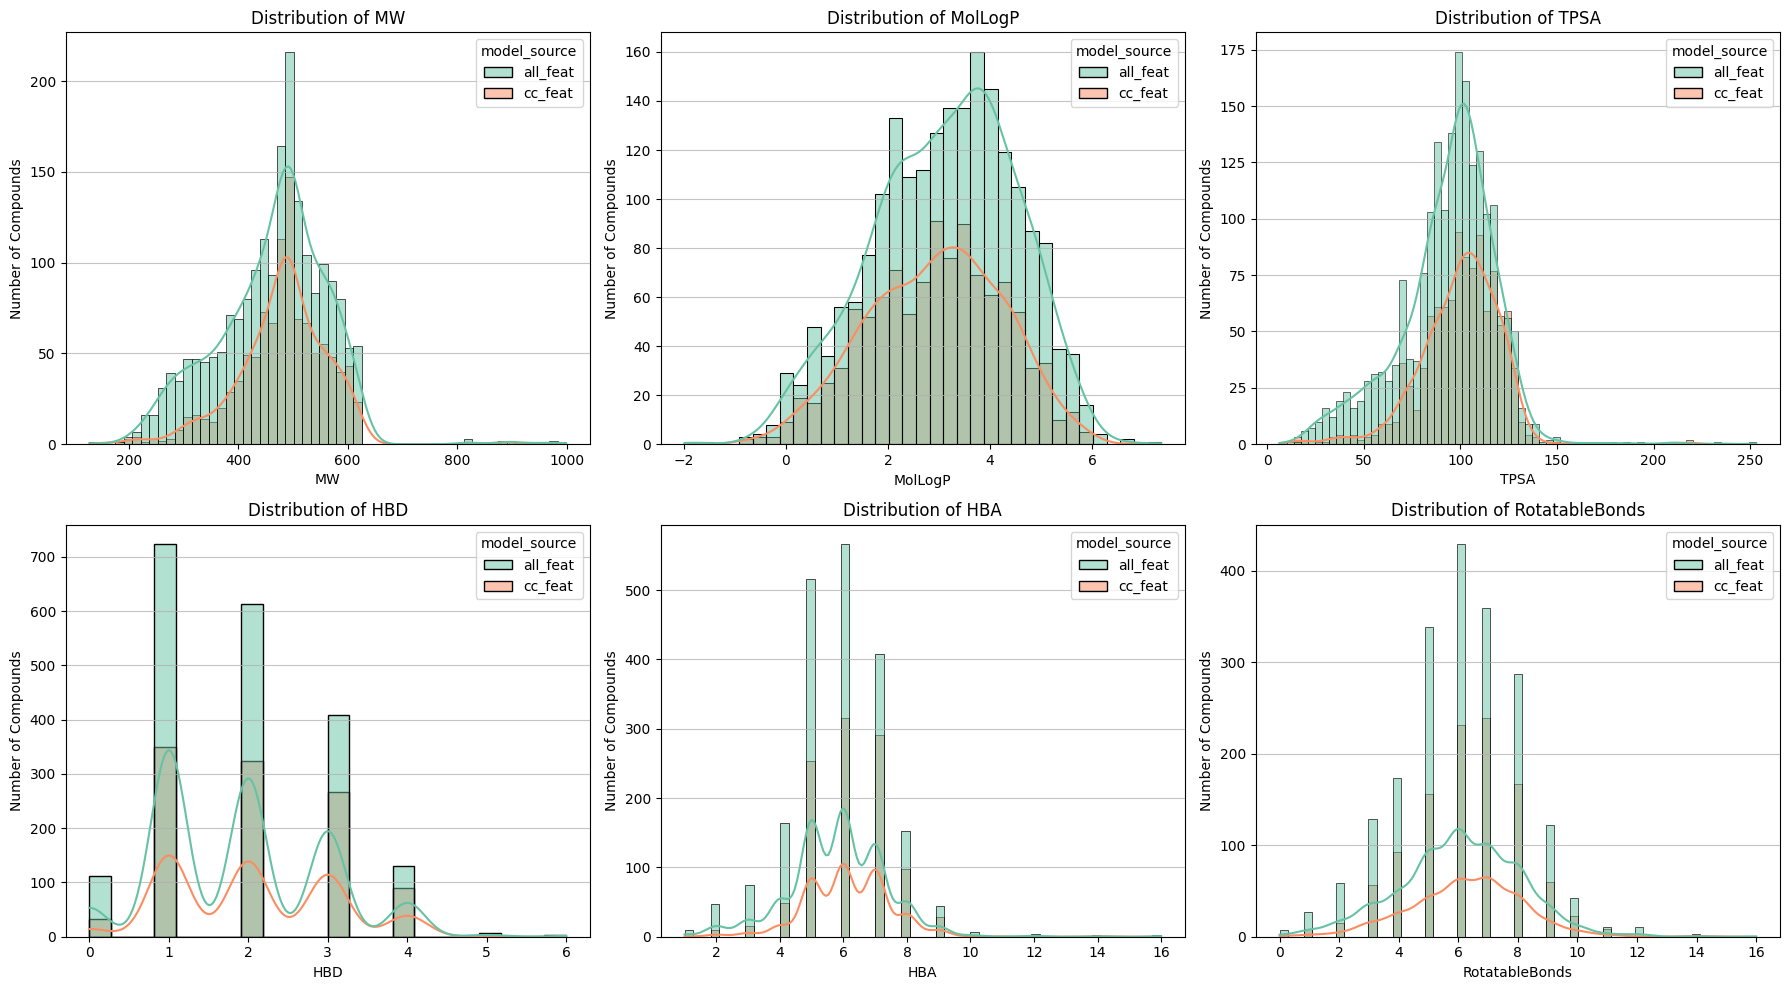


--- Statistical Test (MW) ---
Mean MW (All Feat.): 462.91
Mean MW (Cell Feat.): 481.31
T-statistic: -5.36
P-value: 0.000
There is a statistically significant difference in MW between the two models' predictions.

--- Statistical Test (MolLogP) ---
Mean MolLogP (All Feat.): 3.10
Mean MolLogP (Cell Feat.): 2.93
T-statistic: 3.32
P-value: 0.001
There is a statistically significant difference in MolLogP between the two models' predictions.

--- Statistical Test (TPSA) ---
Mean TPSA (All Feat.): 93.55
Mean TPSA (Cell Feat.): 100.02
T-statistic: -7.66
P-value: 0.000
There is a statistically significant difference in TPSA between the two models' predictions.

Not enough data to perform statistical test for HBD.

Not enough data to perform statistical test for HBA.

--- Statistical Test (RotatableBonds) ---
Mean RotatableBonds (All Feat.): 6.06
Mean RotatableBonds (Cell Feat.): 6.27
T-statistic: -2.77
P-value: 0.006
There is a statistically significant difference in RotatableBonds between the

In [93]:
get_descriptors(tp_df)

## False Positives:

In [95]:
fp_df = unique_and_overlapping(all_fp, cc_fp)

Unique compounds - All Feature Model: 277
Unique compounds - Cell Count Model: 146
Overlap between models: 97.38% (15713/16136)


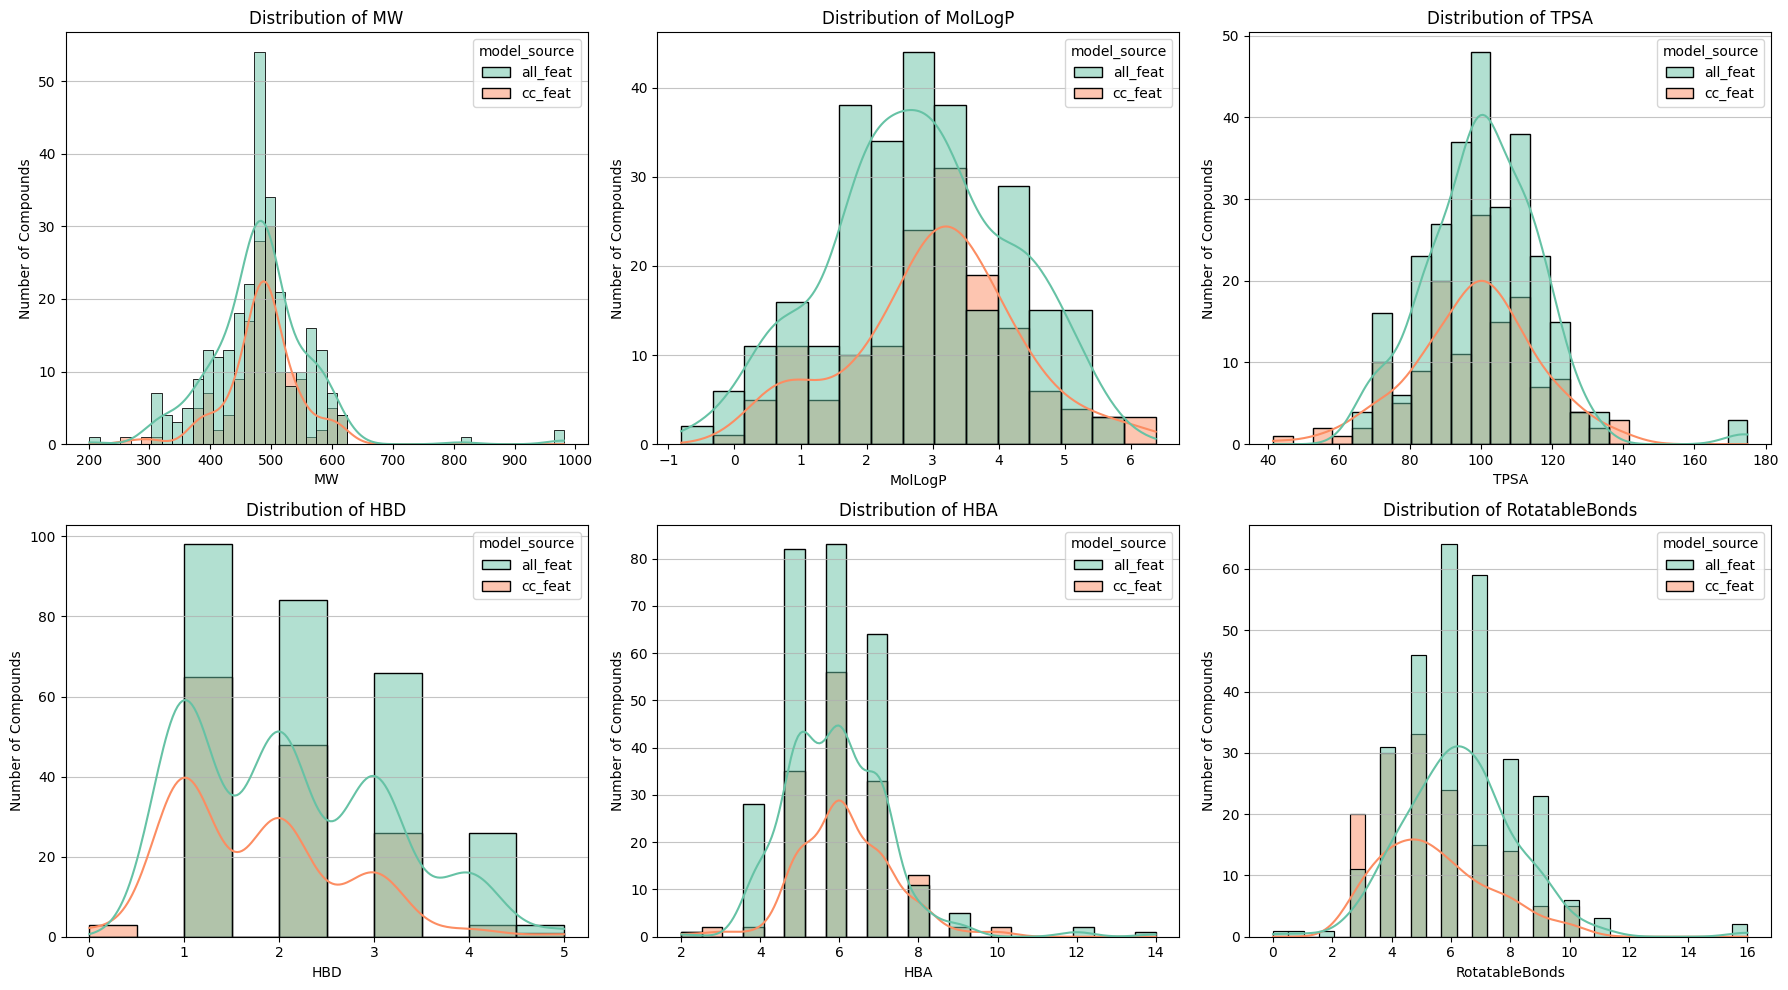


--- Statistical Test (MW) ---
Mean MW (All Feat.): 481.63
Mean MW (Cell Feat.): 485.83
T-statistic: -0.60
P-value: 0.550
No statistically significant difference in MW between the two models' predictions.

--- Statistical Test (MolLogP) ---
Mean MolLogP (All Feat.): 2.79
Mean MolLogP (Cell Feat.): 3.03
T-statistic: -1.81
P-value: 0.071
No statistically significant difference in MolLogP between the two models' predictions.

--- Statistical Test (TPSA) ---
Mean TPSA (All Feat.): 100.59
Mean TPSA (Cell Feat.): 98.36
T-statistic: 1.29
P-value: 0.200
No statistically significant difference in TPSA between the two models' predictions.

Not enough data to perform statistical test for HBD.

Not enough data to perform statistical test for HBA.

--- Statistical Test (RotatableBonds) ---
Mean RotatableBonds (All Feat.): 6.32
Mean RotatableBonds (Cell Feat.): 5.49
T-statistic: 4.33
P-value: 0.000
There is a statistically significant difference in RotatableBonds between the two models' predictions.

In [96]:
get_descriptors(fp_df)

## True Negatives:

In [97]:
tn_df = unique_and_overlapping(all_tn, cc_tn)

Unique compounds - All Feature Model: 53
Unique compounds - Cell Count Model: 3
Overlap between models: 99.65% (16101/16157)


- There are not enough unique compounds between the two models to perform productive distribution comparisons.

In [99]:
# get_descriptors(tn_df)

## False Negatives:

In [100]:
fn_df = unique_and_overlapping(all_fn, cc_fn)

Unique compounds - All Feature Model: 1476
Unique compounds - Cell Count Model: 1613
Overlap between models: 51.94% (3339/6428)


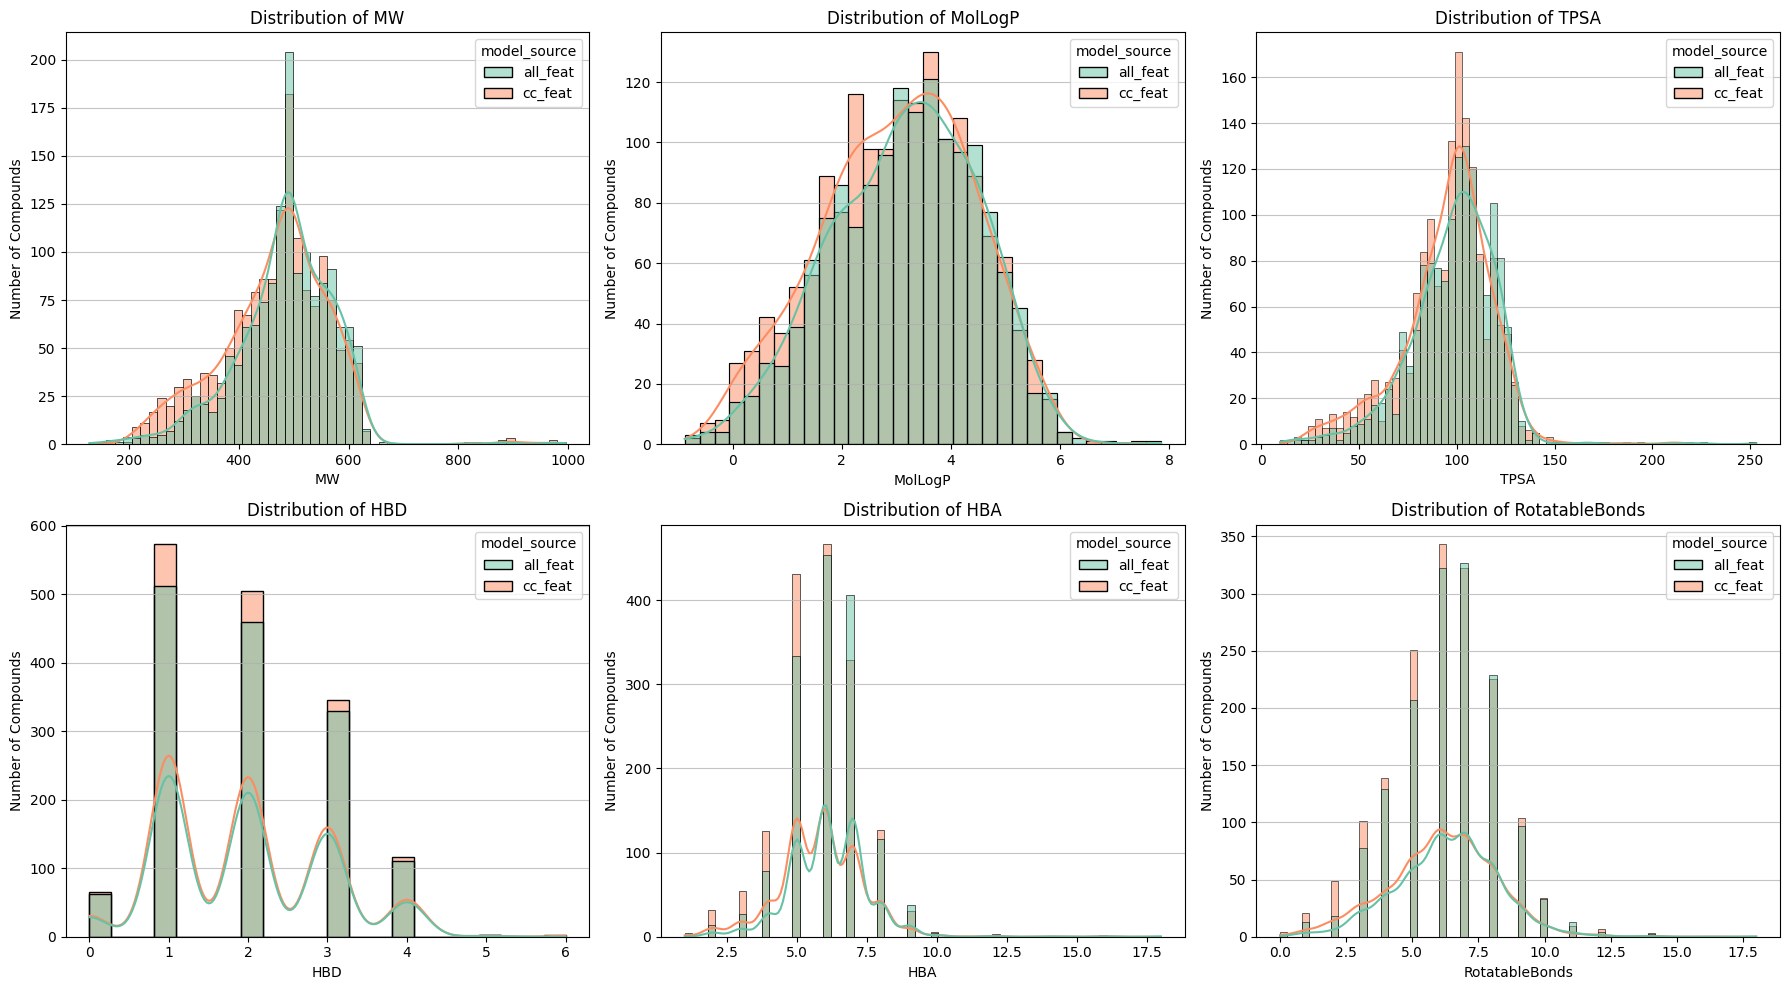


--- Statistical Test (MW) ---
Mean MW (All Feat.): 485.44
Mean MW (Cell Feat.): 466.02
T-statistic: 5.74
P-value: 0.000
There is a statistically significant difference in MW between the two models' predictions.

--- Statistical Test (MolLogP) ---
Mean MolLogP (All Feat.): 3.16
Mean MolLogP (Cell Feat.): 3.01
T-statistic: 3.00
P-value: 0.003
There is a statistically significant difference in MolLogP between the two models' predictions.

--- Statistical Test (TPSA) ---
Mean TPSA (All Feat.): 98.43
Mean TPSA (Cell Feat.): 95.21
T-statistic: 3.91
P-value: 0.000
There is a statistically significant difference in TPSA between the two models' predictions.

Not enough data to perform statistical test for HBD.

Not enough data to perform statistical test for HBA.

--- Statistical Test (RotatableBonds) ---
Mean RotatableBonds (All Feat.): 6.33
Mean RotatableBonds (Cell Feat.): 6.11
T-statistic: 3.02
P-value: 0.003
There is a statistically significant difference in RotatableBonds between the two

In [101]:
get_descriptors(fn_df)

# Structural Analysis:

### Scaffolds:

In [117]:
from rdkit.Chem.Scaffolds import MurckoScaffold

In [177]:
def get_murcko_scaffold(mol): 
    if mol is None: 
        return None 
    try: 
        scaffold = MurckoScaffold.GetScaffoldForMol(mol) 
        return scaffold # Chem.MolToSmiles(scaffold) 
    except Exception: 
        return None # Handle cases where a scaffold cannot be generated 

def scaffold_analysis(df):
    df['Murcko_Scaffold_Mol'] = df['Molecule_Object'].apply(get_murcko_scaffold) 
    df['Murcko_Scaffold_SMILES'] = df['Murcko_Scaffold_Mol'].apply(Chem.MolToSmiles)
    print("\n--- Murcko Scaffold Analysis ---") 
    # print("Murcko Scaffolds extracted:") 
    # print(df[['smiles', 'Murcko_Scaffold', 'model_source']]) # Identify unique scaffolds and their counts for each model 
    
    scaffold_counts_A = df[df['model_source'] == 'all_feat']['Murcko_Scaffold_SMILES'].value_counts() 
    scaffold_counts_B = df[df['model_source'] == 'cc_feat']['Murcko_Scaffold_SMILES'].value_counts() 
    print("\nTop 5 Scaffolds in Model A predictions:") 
    print(scaffold_counts_A.head()) 
    print("\nTop 5 Scaffolds in Model B predictions:") 
    print(scaffold_counts_B.head()) 
    
    # Find scaffolds unique to each model 
    unique_scaffolds_A = list(set(scaffold_counts_A.index) - set(scaffold_counts_B.index))
    unique_scaffolds_B = list(set(scaffold_counts_B.index) - set(scaffold_counts_A.index))
    common_scaffolds = list(set(scaffold_counts_A.index).intersection(set(scaffold_counts_B.index)))
    
    print(f"\nNumber of unique scaffolds in All Feature Model predictions: {len(unique_scaffolds_A)}") 
    print(f"Number of unique scaffolds in Cell Count Model predictions: {len(unique_scaffolds_B)}") 
    print(f"Number of common scaffolds: {len(common_scaffolds)}") 

    return unique_scaffolds_A, unique_scaffolds_B, common_scaffolds

### Fingerprints:

In [152]:
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

from rdkit.Chem import rdFingerprintGenerator
from rdkit.DataStructs import FingerprintSimilarity

In [164]:
mfpgen = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)

def get_morgan_fingerprint(mol): 
    if mol is None: 
        return None 
    return mfpgen.GetFingerprint(mol)
    # AllChem.GetMorganFingerprintAsBitVect(mol, radius, nBits=nBits) 

def perform_pca(df, fingerprints_matrix):
    # PCA (Principal Component Analysis):
    print("\nPerforming PCA...") 
    pca = PCA(n_components=2) 
    pca_coords = pca.fit_transform(fingerprints_matrix) 
    df['PCA1'] = pca_coords[:, 0] 
    df['PCA2'] = pca_coords[:, 1] 

    # Plot PCA 
    plt.figure(figsize=(6, 4)) 
    sns.scatterplot(x='PCA1', 
                    y='PCA2', 
                    hue='model_source', 
                    data=df, 
                    palette='Set2', 
                    s=20, 
                    alpha=0.8) 
    plt.title('Chemical Space (PCA) of Predicted Compounds') 
    plt.xlabel(f'PCA Component 1 ({pca.explained_variance_ratio_[0]*100:.2f}%)') 
    plt.ylabel(f'PCA Component 2 ({pca.explained_variance_ratio_[1]*100:.2f}%)') 
    plt.grid(True, linestyle='--', alpha=0.6) 
    plt.tight_layout() 
    plt.show() 

def perform_tsne(df, fingerprints_matrix):
    # t-SNE (t-distributed Stochastic Neighbor Embedding): Better for non-linear relationships
    # Adjust 'n_iter' and 'perplexity' for better visualization. 
    print("Performing t-SNE...") 
    tsne = TSNE(n_components=2, random_state=42, perplexity=10) # perplexity must be less than n_samples 
    tsne_coords = tsne.fit_transform(fingerprints_matrix) 
    df['tSNE1'] = tsne_coords[:, 0] 
    df['tSNE2'] = tsne_coords[:, 1] 

    # Plot t-SNE 
    plt.figure(figsize=(6, 4)) 
    sns.scatterplot(x='tSNE1', 
                    y='tSNE2', 
                    hue='model_source', 
                    data=df, 
                    palette='Set2', 
                    s=20, 
                    alpha=0.8) 
    plt.title('Chemical Space (t-SNE) of Predicted Compounds') 
    plt.xlabel('t-SNE Component 1') 
    plt.ylabel('t-SNE Component 2') 
    plt.grid(True, linestyle='--', alpha=0.6) 
    plt.tight_layout() 
    plt.show() 

def calculate_average_pairwise_similarity(fingerprints): 
    if len(fingerprints) < 2: 
        return 0.0 # Cannot calculate similarity for less than 2 compounds 
    similarities = [] 
    for i in range(len(fingerprints)): 
        for j in range(i + 1, len(fingerprints)): 
            sim = FingerprintSimilarity(fingerprints[i], fingerprints[j]) 
            similarities.append(sim) 
                
    return np.mean(similarities) if similarities else 0.0 

def fprint_analysis(df):
    df['Morgan_FP'] = df['Molecule_Object'].apply(get_morgan_fingerprint) 
    # Filter out any rows where fingerprint generation failed (e.g., None mol object) 
    df = df.dropna(subset=['Morgan_FP']).copy() 

    # Convert fingerprints to a NumPy array for PCA/t-SNE 
    fingerprints_matrix = np.array([list(map(int, fp.ToBitString())) for fp in df['Morgan_FP']]) 

    # Perform and plot PCA and t-SNE:
    perform_pca(df, fingerprints_matrix)
    perform_tsne(df, fingerprints_matrix)

    # Diversity Analysis (Average Pairwise Tanimoto Similarity) 
    # This provides a measure of how diverse the compounds are within each list
    fps_A = df[df['model_source'] == 'all_feat']['Morgan_FP'].tolist() 
    fps_B = df[df['model_source'] == 'cc_feat']['Morgan_FP'].tolist() 
    avg_sim_A = calculate_average_pairwise_similarity(fps_A) 
    avg_sim_B = calculate_average_pairwise_similarity(fps_B) 
    print(f"\n--- Diversity Analysis (Average Pairwise Tanimoto Similarity) ---") 
    print(f"Average Pairwise Tanimoto Similarity for the all feature model: {avg_sim_A:.3f}") 
    print(f"Average Pairwise Tanimoto Similarity for the cell count model: {avg_sim_B:.3f}") 
    
    if avg_sim_A < avg_sim_B: 
        print("All feature model's predicted compounds appear more diverse (lower average similarity).") 
    elif avg_sim_B < avg_sim_A: 
        print("Cell count model's predicted compounds appear more diverse (lower average similarity).") 
    else: 
        print("Both models' predicted compounds have similar levels of diversity.") 

## True Positives:

In [178]:
all_feat_scaff, cc_feat_scaf, common_scaf = scaffold_analysis(tp_df)


--- Murcko Scaffold Analysis ---

Top 5 Scaffolds in Model A predictions:
Murcko_Scaffold_SMILES
O=C1NCCCCNCCOc2ccccc21                          33
O=C(Nc1ccccc1)Nc1ccc2c(c1)C(=O)NCCCCNCCO2       17
O=C1NCCCOCc2ccccc2-c2c1[nH]c1ccccc21            14
O=C1NCCCOCCCCCOc2ccc(NS(=O)(=O)c3ccccc3)cc21    13
O=C1NCCCCN(Cc2ccccc2)CCOc2ccccc21               12
Name: count, dtype: int64

Top 5 Scaffolds in Model B predictions:
Murcko_Scaffold_SMILES
O=C1NCCCCNCCOc2ccccc21                          17
O=C1NCCCOCCCCCOc2ccccc21                        16
O=C(Nc1ccccc1)Nc1ccc2c(c1)C(=O)NCCCCNCCO2       15
O=C1NCCCCN(Cc2ccccc2)CCOc2ccccc21               11
O=C1NCCCOCCCCCOc2ccc(NS(=O)(=O)c3ccccc3)cc21    10
Name: count, dtype: int64

Number of unique scaffolds in All Feature Model predictions: 1175
Number of unique scaffolds in Cell Count Model predictions: 528
Number of common scaffolds: 233


In [180]:
tp_df.head(2)

,smiles,model_source,Molecule_Object,MW,MolLogP,TPSA,HBD,HBA,RotatableBonds,FormalCharge,Murcko_Scaffold,Morgan_FP,Murcko_Scaffold_Mol,Murcko_Scaffold_SMILES
0,C\C=C\Cn1c(SCc2ccccc2)nc2n(C)c(=O)[nH]c(=O)c12,all_feat,<rdkit.Chem.rdchem.Mol object at 0x000001B307A...,342.424,2.2917,72.68,1,6,5,0,O=c1[nH]c(=O)c2[nH]c(SCc3ccccc3)nc2[nH]1,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...",<rdkit.Chem.rdchem.Mol object at 0x000001B307A...,O=c1[nH]c(=O)c2[nH]c(SCc3ccccc3)nc2[nH]1
1,C[C@H](CO)N1C[C@@H](C)[C@@H](CN(C)Cc2ccc3OCCOc...,all_feat,<rdkit.Chem.rdchem.Mol object at 0x000001B307A...,487.601,1.7058,102.18,1,9,6,0,O=C1CCCn2nncc2CO[C@H](CNCc2ccc3c(c2)OCCO3)CCN1,"[0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, ...",<rdkit.Chem.rdchem.Mol object at 0x000001B307A...,O=C1CCCn2nncc2CO[C@H](CNCc2ccc3c(c2)OCCO3)CCN1



Performing PCA...


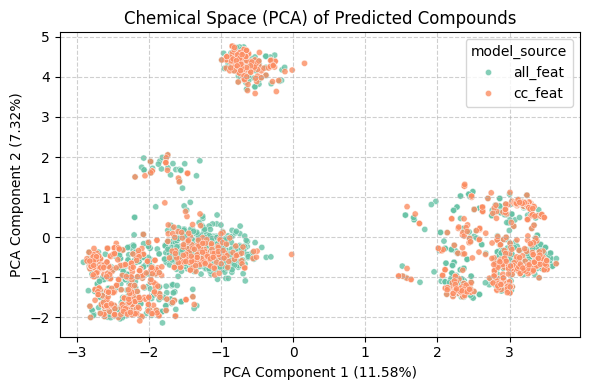

Performing t-SNE...


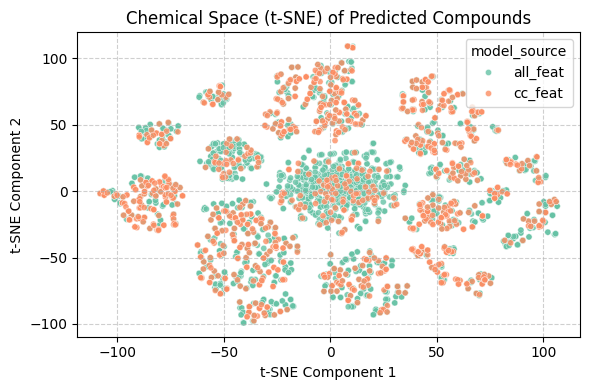


--- Diversity Analysis (Average Pairwise Tanimoto Similarity) ---
Average Pairwise Tanimoto Similarity for the all feature model: 0.178
Average Pairwise Tanimoto Similarity for the cell count model: 0.212
All feature model's predicted compounds appear more diverse (lower average similarity).


In [165]:
fprint_analysis(tp_df)


Performing PCA...


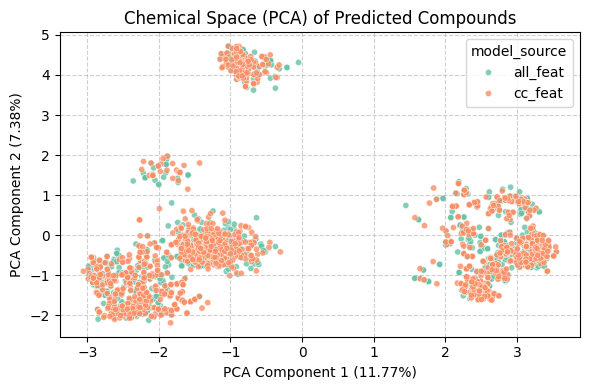

Performing t-SNE...


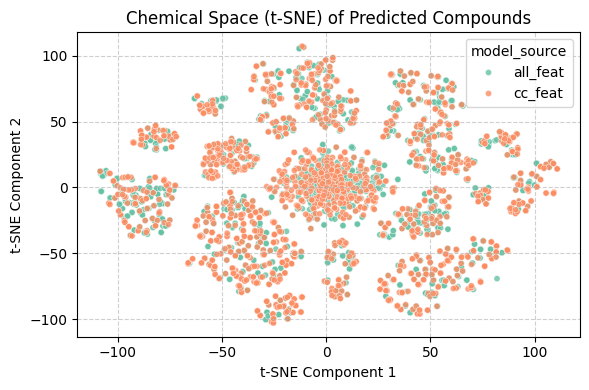


--- Diversity Analysis (Average Pairwise Tanimoto Similarity) ---
Average Pairwise Tanimoto Similarity for the all feature model: 0.202
Average Pairwise Tanimoto Similarity for the cell count model: 0.184
Cell count model's predicted compounds appear more diverse (lower average similarity).


In [187]:
fprint_analysis(fn_df)

## Further scaffold analysis:

In [213]:
def get_scaffold_properties(scaffold_mol):
    if scaffold_mol is None:
        return None, None, None, None, None

    scaffold_mw = Descriptors.MolWt(scaffold_mol)
    scaffold_num_rings = rdMolDescriptors.CalcNumRings(scaffold_mol)

    # Aromaticity: Check is all ring are aromatic:
    # Descriptors.NumRings counts aromatic rings.
    # if NumAromaticRings == NumRings and NumRings > 0 then it's fuly aromatic
    num_aromatic_rings = rdMolDescriptors.CalcNumAromaticRings(scaffold_mol)
    is_aromatic = 1 if num_aromatic_rings > 0 and num_aromatic_rings == scaffold_num_rings else 0

    # Prescence of Heteroatoms (N, O, S):
    num_heteroatoms = 0
    for atom in scaffold_mol.GetAtoms():
        if atom.GetAtomicNum() in [7, 8, 16]: # 7=nitrogen, 8=oxygen, 16=sulphur
            num_heteroatoms += 1
    has_heteroatoms = 1 if num_heteroatoms > 0 else 0

    return scaffold_mw, scaffold_num_rings, is_aromatic, num_heteroatoms, has_heteroatoms

def scaffold_sub_analysis(df):
    df[['Scaffold_MW', 'Scaffold_NumRings', 'Scaffold_IsAromatic', 
        'Scaffold_NumHeteroatoms', 'Scaffold_HasHeteroatom']] = df['Murcko_Scaffold_Mol'].apply(
                                                                                lambda mol: pd.Series(get_scaffold_properties(mol)))
        
    continous_props = ['Scaffold_MW', 'Scaffold_NumRings', 'Scaffold_NumHeteroatoms']
    binary_props = ['Scaffold_IsAromatic', 'Scaffold_HasHeteroatom']

    print("\nBinary Properties:")
    for prop in binary_props:
        print(f"-------{prop}-------")
        counts = df.groupby('model_source')[prop].value_counts(normalize=False)
        percents = df.groupby('model_source')[prop].value_counts(normalize=True)*100
        df_temp = pd.DataFrame({'Count': counts, 'Percentage': percents}).unstack(fill_value=0)
        print(df_temp)

    # Vizualize continuous properties:
    fig, axes = plt.subplots(1, 3, figsize=(18, 10))
    axes = axes.flatten()
    
    for i, prop in enumerate(continous_props):
        sns.histplot(data=df,
                     x=prop,
                     hue='model_source',
                     kde=True,
                     palette='Set2',
                     multiple='layer',
                     ax=axes[i])
        axes[i].set_title(f'{prop}')
        axes[i].set_xlabel(prop)
        axes[i].set_ylabel('Number of Scaffolds')
        axes[i].grid(axis='y', alpha=0.75)
    plt.tight_layout()
    plt.show()
    

In [205]:
get_scaffold_properties(tp_df.iloc[0].Murcko_Scaffold_Mol)

(274.30500000000006, 3, 1, 7, 1)


Binary Properties:
-------Scaffold_IsAromatic-------
                    Count      Percentage           
Scaffold_IsAromatic   0.0  1.0        0.0        1.0
model_source                                        
all_feat             1720  279  86.043022  13.956978
cc_feat              1014   51  95.211268   4.788732
-------Scaffold_HasHeteroatom-------
                       Count       Percentage           
Scaffold_HasHeteroatom   0.0   1.0        0.0        1.0
model_source                                            
all_feat                  15  1984   0.750375  99.249625
cc_feat                    1  1064   0.093897  99.906103


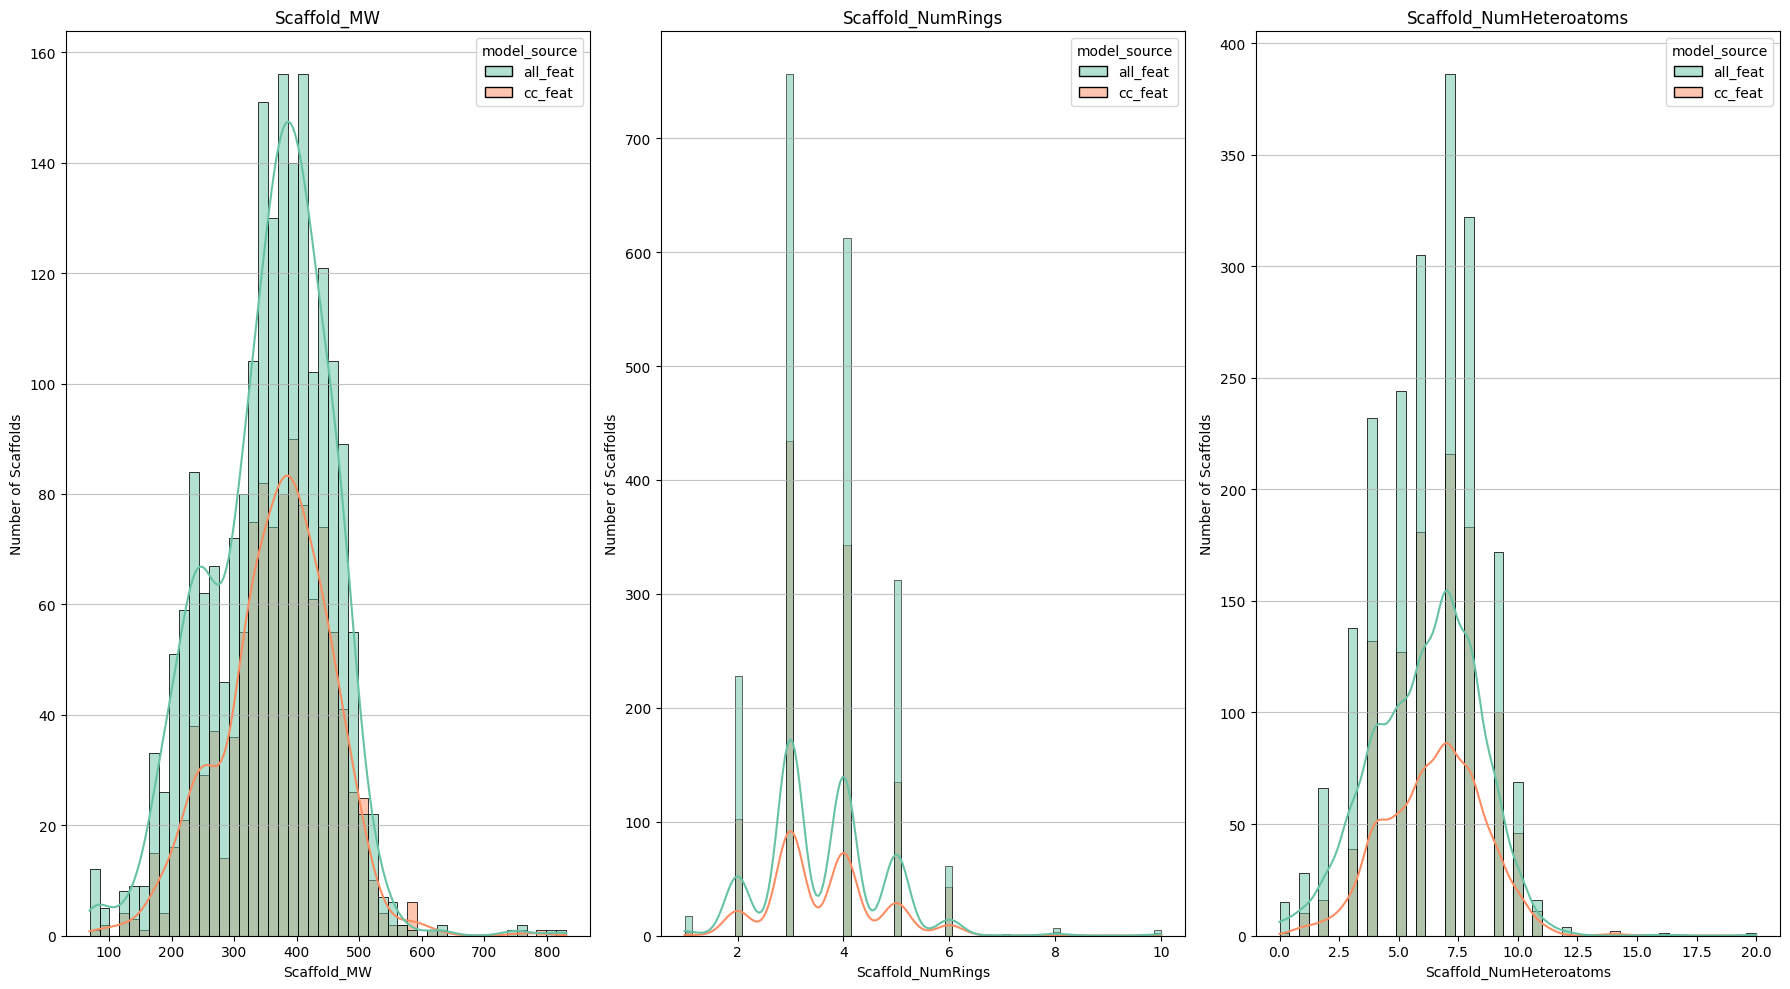

In [214]:
scaffold_sub_analysis(tp_df)    